In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('height-weight.csv')

In [3]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


In [7]:
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


In [9]:
df.describe()

,Weight,Height
count,23.000000,23.000000
mean,73.826087,158.391304
std,17.872407,19.511626
min,45.000000,120.000000
25%,59.000000,142.500000
50%,78.000000,162.000000
75%,86.000000,175.000000
max,105.000000,183.000000


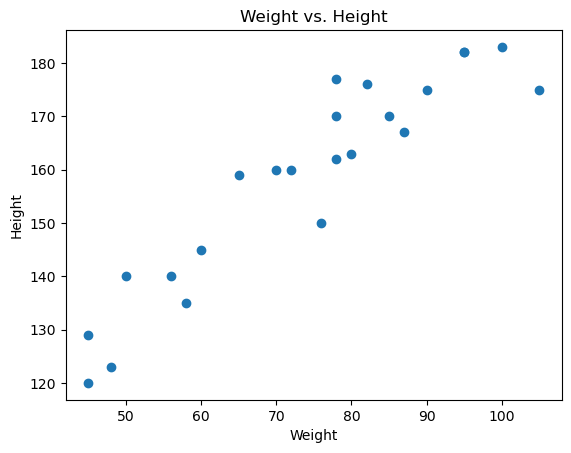

In [11]:
import matplotlib.pyplot as plt

plt.scatter(df["Weight"], df["Height"])

plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("Weight vs. Height")
plt.show()

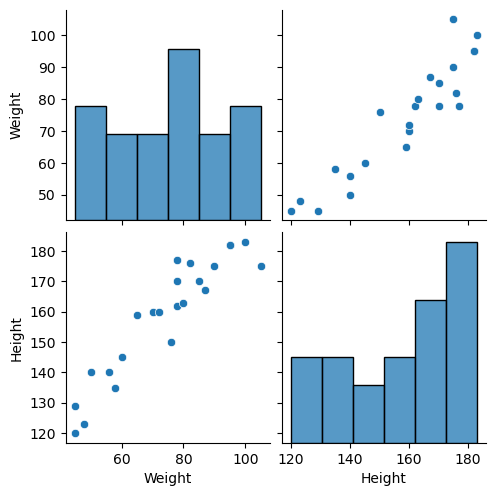

In [12]:
sns.pairplot(df)

In [13]:
X=df[['Weight']]
y=df['Height']

In [15]:
X.shape

(23, 1)

In [17]:
y.shape

(23,)

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
X_train_scaled

array([[-0.87662801],
       [ 1.66773133],
       [ 0.33497168],
       [-1.48242785],
       [ 1.36483141],
       [-1.6641678 ],
       [-0.75546804],
       [-0.1496682 ],
       [ 0.21381171],
       [-1.36126788],
       [-0.99778797],
       [-0.02850823],
       [ 1.06193149],
       [ 0.57729161],
       [ 0.75903157],
       [ 0.88019153],
       [ 0.45613165]])

In [24]:
X_test_scaled

array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [28]:
print(model.intercept_)

156.47058823529412


In [29]:
print(model.coef_)

[17.2982057]


In [33]:
y_pred = model.predict(X_test_scaled)

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [35]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

In [36]:
mae

9.665125886795005

In [37]:
rmse

10.716374991212605

In [38]:
r2

0.7360826717981276

In [45]:
new_weight = 90

# 1. Reshape into 2D (1 sample, 1 feature) and scale with the fitted scaler
new_weight_scaled = scaler.transform(np.array([[new_weight]]))

# 2. Predict height and grab the single value ([0])
pred_height = model.predict(new_weight_scaled)[0]
print(pred_height)

174.8400975262864


e:\anaconda\envs\abdullah\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
